In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("CleanedStudentPerformance.csv")

print(df.head())

   gender Race_Ethnicity  Parental_Education         lunch Test_Preparation  \
0  female        group B   bachelor's degree      standard             none   
1  female        group C        some college      standard        completed   
2  female        group B     master's degree      standard             none   
3    male        group A  associate's degree  free/reduced             none   
4    male        group C        some college      standard             none   

   Math_Score  Reading_Score  Writing_Score  Average_Score        Performance  
0   66.029146       72.00000           74.0      70.676382            Average  
1   69.000000       69.18191           88.0      75.393970            Average  
2   66.029146       95.00000           93.0      84.676382               Good  
3   47.000000       69.18191           44.0      53.393970  Needs Improvement  
4   66.029146       78.00000           75.0      73.009715            Average  


In [3]:
total_students = len(df)

print("Total Number of Students:", total_students)

Total Number of Students: 1000


In [4]:
math_average = df["Math_Score"].mean()
reading_average = df["Reading_Score"].mean()
writing_average = df["Writing_Score"].mean()

print("Math Average:", math_average)
print("Reading Average:", reading_average)
print("Writing Average:", writing_average)

Math Average: 66.02914572864321
Reading Average: 69.1819095477387
Writing Average: 68.07939698492461


In [5]:
top_5_students = df.sort_values(
    by="Average_Score",
    ascending=False
).head(5)

print(top_5_students[[
    "Math_Score",
    "Reading_Score",
    "Writing_Score",
    "Average_Score",
    "Performance"
]])

     Math_Score  Reading_Score  Writing_Score  Average_Score Performance
916       100.0          100.0          100.0     100.000000   Excellent
962       100.0          100.0          100.0     100.000000   Excellent
458       100.0          100.0          100.0     100.000000   Excellent
114        99.0          100.0          100.0      99.666667   Excellent
712        98.0          100.0           99.0      99.000000   Excellent


In [6]:
students_needing_improvement = df[
    df["Performance"] == "Needs Improvement"
]

print(students_needing_improvement[[
    "Math_Score",
    "Reading_Score",
    "Writing_Score",
    "Average_Score",
    "Performance"
]])

print("Total Students Needing Improvement:",
      len(students_needing_improvement))

     Math_Score  Reading_Score  Writing_Score  Average_Score  \
3     47.000000       69.18191      44.000000      53.393970   
7     40.000000       69.18191      39.000000      49.393970   
8     66.029146       64.00000      67.000000      65.676382   
9     38.000000       69.18191      50.000000      52.393970   
10    58.000000       54.00000      68.079397      60.026466   
..          ...            ...            ...            ...   
992   55.000000       76.00000      76.000000      69.000000   
993   62.000000       72.00000      74.000000      69.333333   
994   63.000000       63.00000      62.000000      62.666667   
996   62.000000       55.00000      55.000000      57.333333   
997   59.000000       71.00000      65.000000      65.000000   

           Performance  
3    Needs Improvement  
7    Needs Improvement  
8    Needs Improvement  
9    Needs Improvement  
10   Needs Improvement  
..                 ...  
992  Needs Improvement  
993  Needs Improvement  
994  N

In [7]:
subject_averages = df[[
    "Math_Score",
    "Reading_Score",
    "Writing_Score"
]].mean()

highest_subject = subject_averages.idxmax()
highest_average = subject_averages.max()

print("Subject Averages:")
print(subject_averages)

print("\nSubject with Highest Class Average:", highest_subject)
print("Highest Class Average:", highest_average)

Subject Averages:
Math_Score       66.029146
Reading_Score    69.181910
Writing_Score    68.079397
dtype: float64

Subject with Highest Class Average: Reading_Score
Highest Class Average: 69.1819095477387


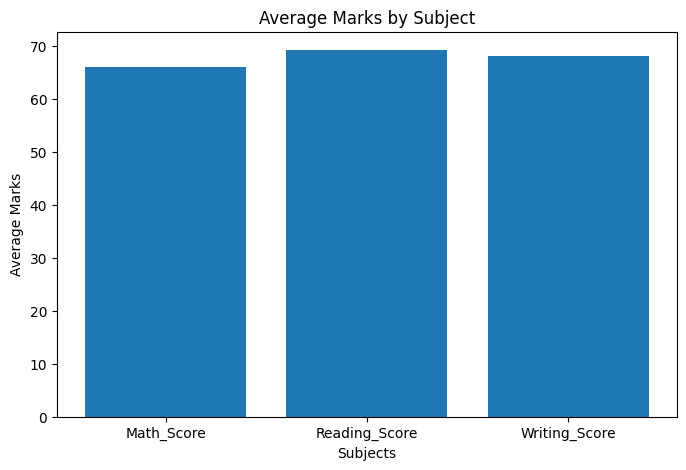

In [14]:
subject_averages = df[[
    "Math_Score",
    "Reading_Score",
    "Writing_Score"
]].mean()

plt.figure(figsize=(8, 5))

plt.bar(subject_averages.index, subject_averages.values)

plt.xlabel("Subjects")
plt.ylabel("Average Marks")
plt.title("Average Marks by Subject")
plt.savefig("subject_average.png", dpi=300, bbox_inches="tight")
plt.show()

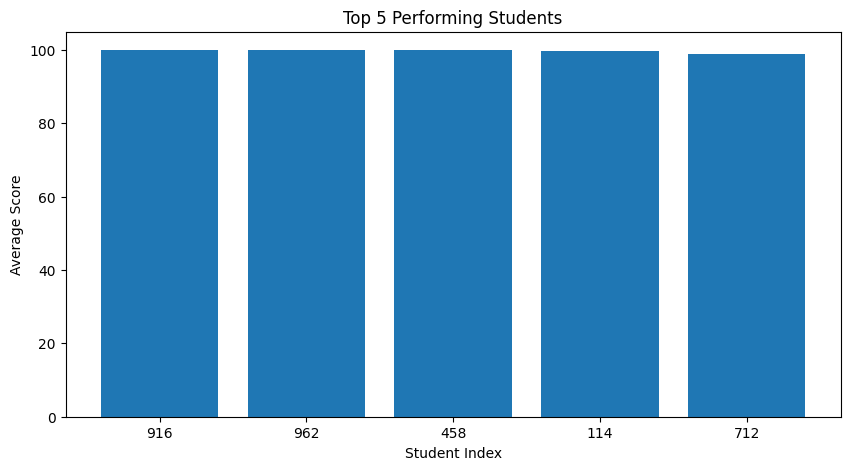

In [13]:
plt.figure(figsize=(10, 5))

plt.bar(
    top_5_students.index.astype(str),
    top_5_students["Average_Score"]
)

plt.xlabel("Student Index")
plt.ylabel("Average Score")
plt.title("Top 5 Performing Students")
plt.savefig("top_5_students.png", dpi=300, bbox_inches="tight")
plt.show()

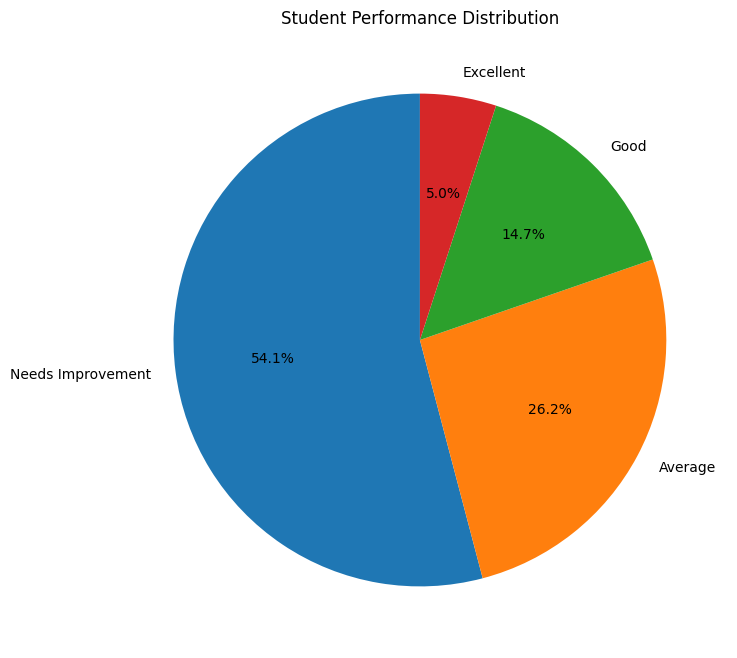

In [12]:
performance_counts = df["Performance"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    performance_counts,
    labels=performance_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Student Performance Distribution")
plt.savefig("performance_distribution.png", dpi=300, bbox_inches="tight")

plt.show()
